In [2]:
import numpy as np
import matplotlib.pyplot as plt
import time
import pandas as pd

from tensorflow.keras.datasets import fashion_mnist
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)


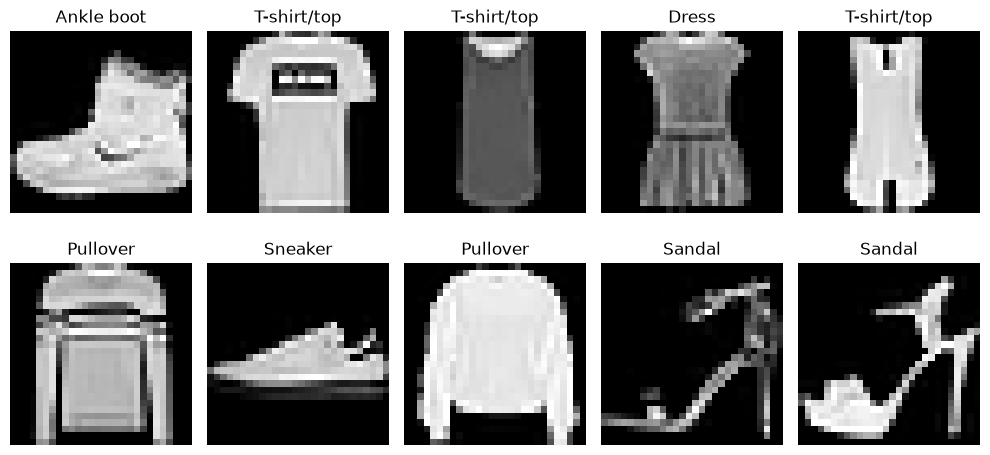

In [4]:
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [5]:
# Normalize pixel values to the range 0 to 1
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Flatten each 28 x 28 image into 784 features
X_train = X_train.reshape(X_train.shape[0], 784)
X_test = X_test.reshape(X_test.shape[0], 784)

# Use subsets to reduce computation time
X_train_small = X_train[:10000]
y_train_small = y_train[:10000]

X_test_small = X_test[:2000]
y_test_small = y_test[:2000]

print("Training samples:", X_train_small.shape[0])
print("Testing samples:", X_test_small.shape[0])
print("Features per image:", X_train_small.shape[1])

Training samples: 10000
Testing samples: 2000
Features per image: 784


In [6]:
k_values = [1, 3, 5, 7, 9]

results = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)

    # Train the KNN model
    start_train = time.time()
    knn.fit(X_train_small, y_train_small)
    train_time = time.time() - start_train

    # Predict the test labels
    start_test = time.time()
    y_pred = knn.predict(X_test_small)
    test_time = time.time() - start_test

    # Calculate accuracy
    accuracy = accuracy_score(y_test_small, y_pred)

    results.append({
        "K": k,
        "Accuracy": accuracy,
        "Training Time (s)": train_time,
        "Prediction Time (s)": test_time
    })

    print(f"K = {k}")
    print(f"Accuracy: {accuracy * 100:.2f}%")
    print(f"Training time: {train_time:.4f} seconds")
    print(f"Prediction time: {test_time:.4f} seconds")
    print("-" * 35)

K = 1
Accuracy: 80.75%
Training time: 0.0397 seconds
Prediction time: 0.6032 seconds
-----------------------------------
K = 3
Accuracy: 81.95%
Training time: 0.0072 seconds
Prediction time: 0.4690 seconds
-----------------------------------
K = 5
Accuracy: 82.25%
Training time: 0.0074 seconds
Prediction time: 0.4530 seconds
-----------------------------------
K = 7
Accuracy: 82.60%
Training time: 0.0062 seconds
Prediction time: 0.4538 seconds
-----------------------------------
K = 9
Accuracy: 82.20%
Training time: 0.0068 seconds
Prediction time: 0.4590 seconds
-----------------------------------


In [7]:
import pandas as pd

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

 K  Accuracy  Training Time (s)  Prediction Time (s)
 1    0.8075           0.039660             0.603201
 3    0.8195           0.007185             0.469007
 5    0.8225           0.007358             0.453017
 7    0.8260           0.006232             0.453814
 9    0.8220           0.006849             0.458981


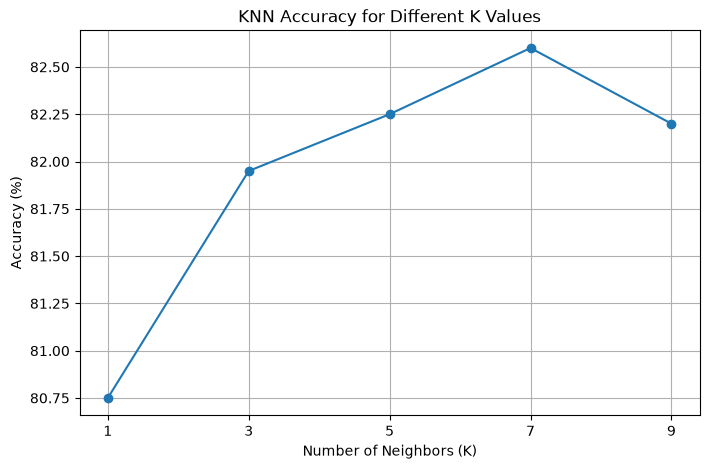

In [8]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["K"],
    results_df["Accuracy"] * 100,
    marker="o"
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Accuracy (%)")
plt.title("KNN Accuracy for Different K Values")
plt.xticks(k_values)
plt.grid(True)
plt.show()

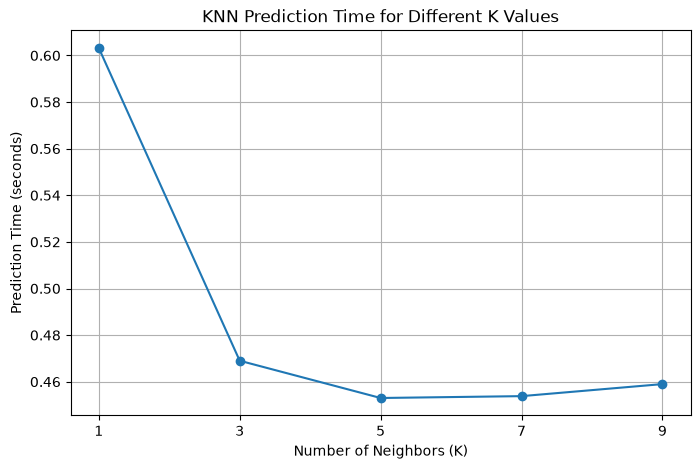

In [9]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["K"],
    results_df["Prediction Time (s)"],
    marker="o"
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Prediction Time (seconds)")
plt.title("KNN Prediction Time for Different K Values")
plt.xticks(k_values)
plt.grid(True)
plt.show()

In [10]:
best_index = results_df["Accuracy"].idxmax()
best_k = int(results_df.loc[best_index, "K"])

best_knn = KNeighborsClassifier(n_neighbors=best_k)
best_knn.fit(X_train_small, y_train_small)

y_pred_best = best_knn.predict(X_test_small)

print("Best K:", best_k)
print("\nClassification Report:\n")

print(classification_report(
    y_test_small,
    y_pred_best,
    labels=list(range(10)),
    target_names=class_names,
    zero_division=0
))

Best K: 7

Classification Report:

              precision    recall  f1-score   support

 T-shirt/top       0.73      0.81      0.77       200
     Trouser       0.99      0.95      0.97       203
    Pullover       0.75      0.78      0.76       214
       Dress       0.86      0.85      0.85       190
        Coat       0.76      0.73      0.74       219
      Sandal       0.99      0.77      0.86       195
       Shirt       0.58      0.58      0.58       197
     Sneaker       0.84      0.94      0.89       200
         Bag       0.97      0.91      0.94       194
  Ankle boot       0.87      0.95      0.91       188

    accuracy                           0.83      2000
   macro avg       0.83      0.83      0.83      2000
weighted avg       0.83      0.83      0.83      2000

